Technological Institute of the Philippines | Quezon City - Computer Engineering
--- | ---
Course Code: | CPE 027
Code Title: | Digital Signal Processing and Application
1st Semester | AY 2026-2027
<u>**Laboratory Activity 12** | **Application for Speech Processing**
**Name** | Adrian Justin Bulambao
**Section** | CPE41S1
**Date Performed**: | October 31, 2026
**Date Submitted**: | November 1, 2026
**Instructor**: | Engr. Leah Belaya

<hr>

1. Graph the signal of the provided three wav files in time domain.

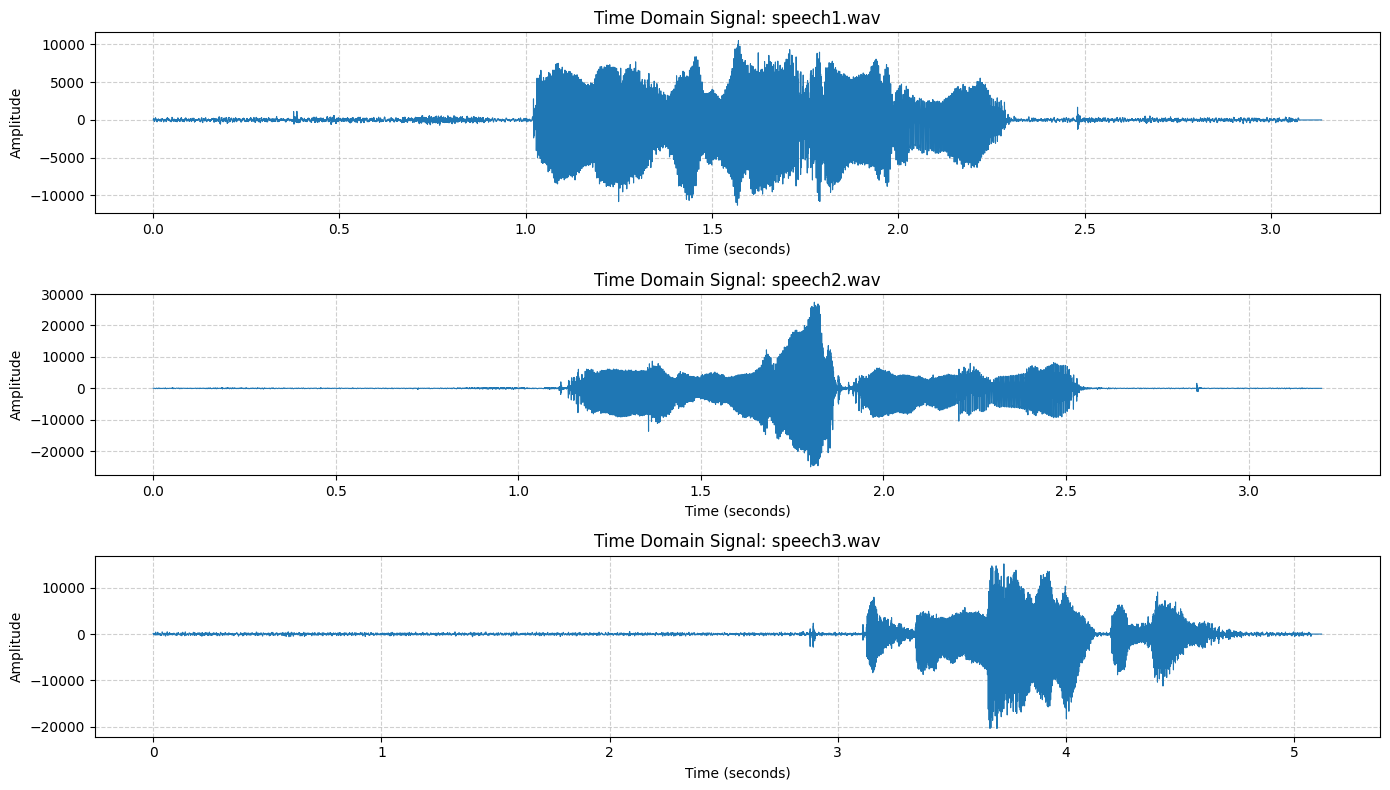

In [ ]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile

# Folder path
folder_path = '/content/drive/MyDrive/CPE 027 - DSP Files/LAB 12/'

# Load the three WAV files
wav_files = sorted(glob.glob(os.path.join(folder_path, '*.wav')))[:3]

# Check if three files are available
if len(wav_files) < 3:
    print("Error: Three WAV files are required.")

else:
    plt.figure(figsize=(14, 8))

    for i, file_path in enumerate(wav_files):

        # Read WAV file
        sr, data = wavfile.read(file_path)

        # Convert stereo to mono if necessary
        if data.ndim > 1:
            data = data.mean(axis=1)

        # Generate time axis
        time = np.arange(len(data)) / sr

        # Plot time-domain signal
        plt.subplot(3, 1, i + 1)
        plt.plot(time, data, color='#1f77b4', linewidth=0.8)

        plt.title(f'Time Domain Signal: {os.path.basename(file_path)}')
        plt.xlabel('Time (seconds)')
        plt.ylabel('Amplitude')
        plt.grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()


2. Sample and quantized each signal. Then, filter the wav files and use Blackman window to prepare the signal for STFT.


Processing: speech1.wav
Sampling Frequency: 16000 Hz
Number of Samples: 50176
Duration: 3.136 seconds


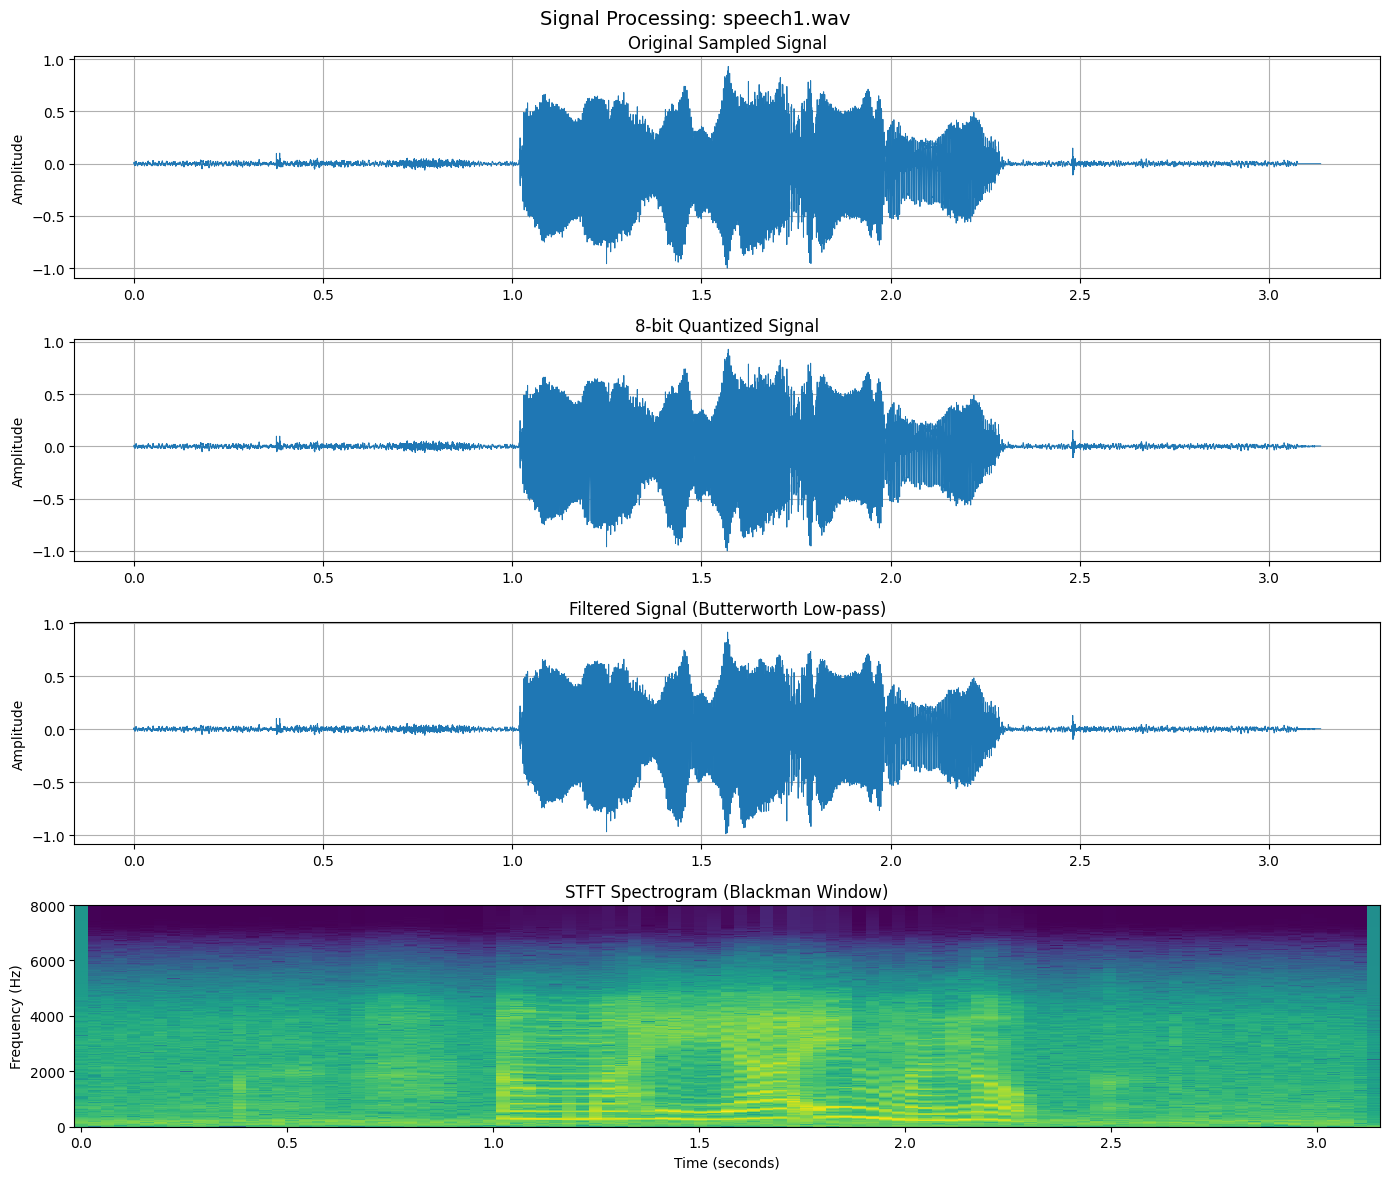


Processing: speech2.wav
Sampling Frequency: 16000 Hz
Number of Samples: 51200
Duration: 3.2 seconds


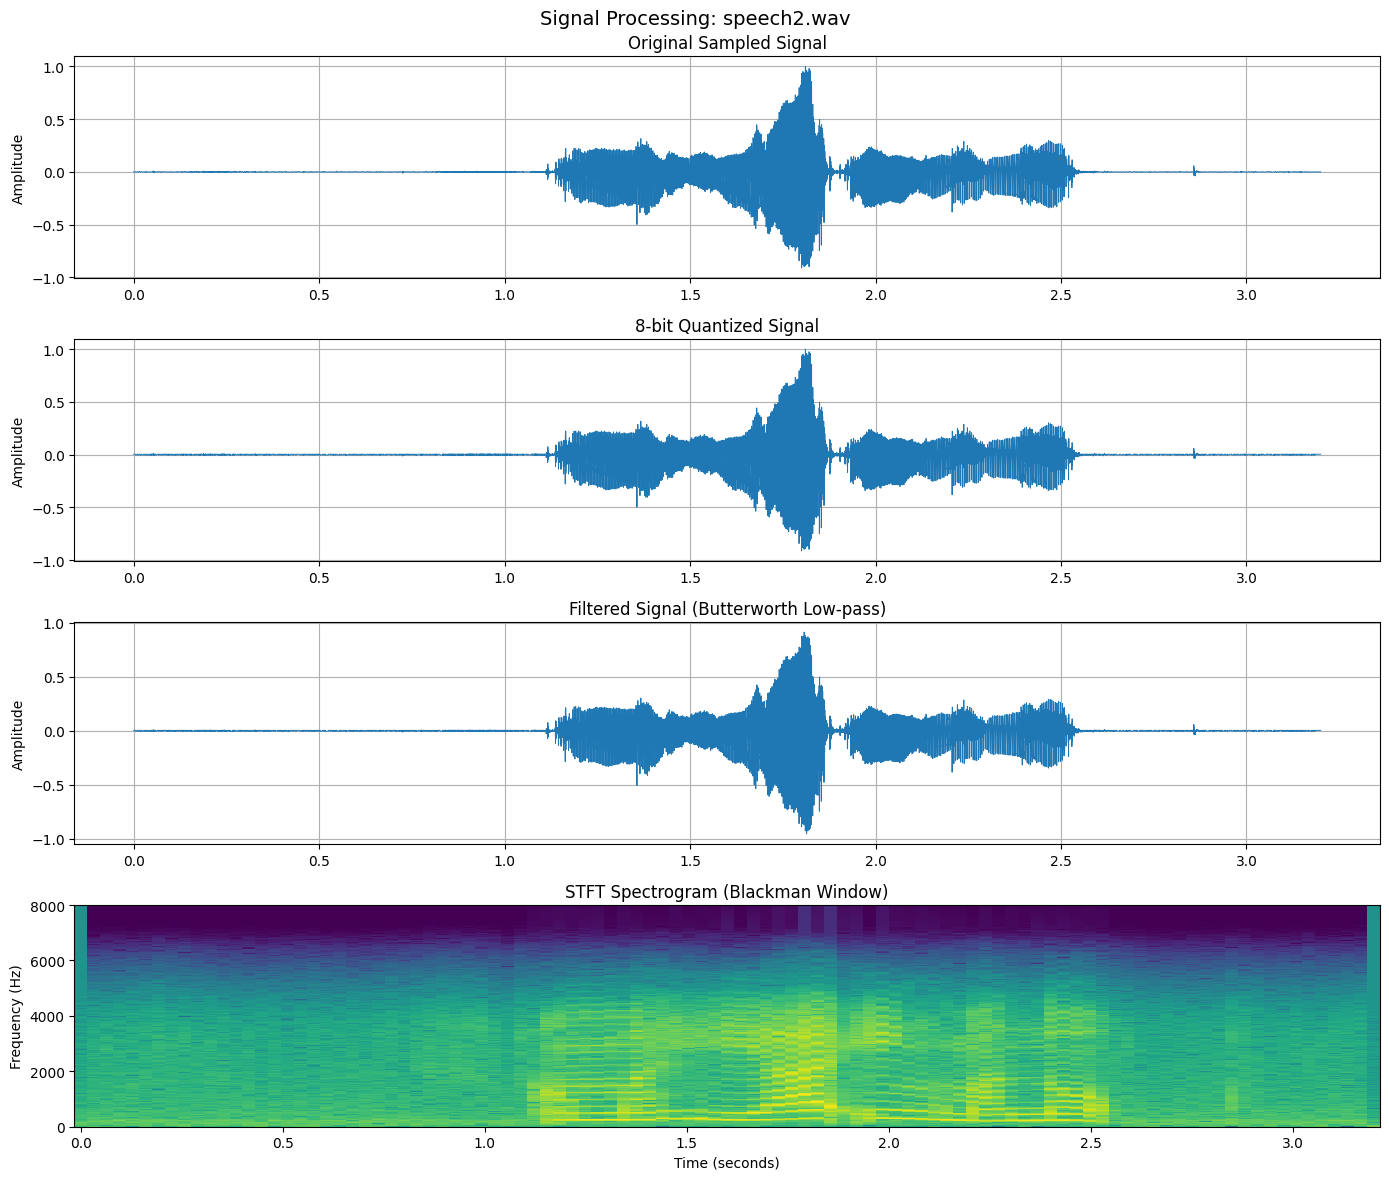


Processing: speech3.wav
Sampling Frequency: 16000 Hz
Number of Samples: 81920
Duration: 5.12 seconds


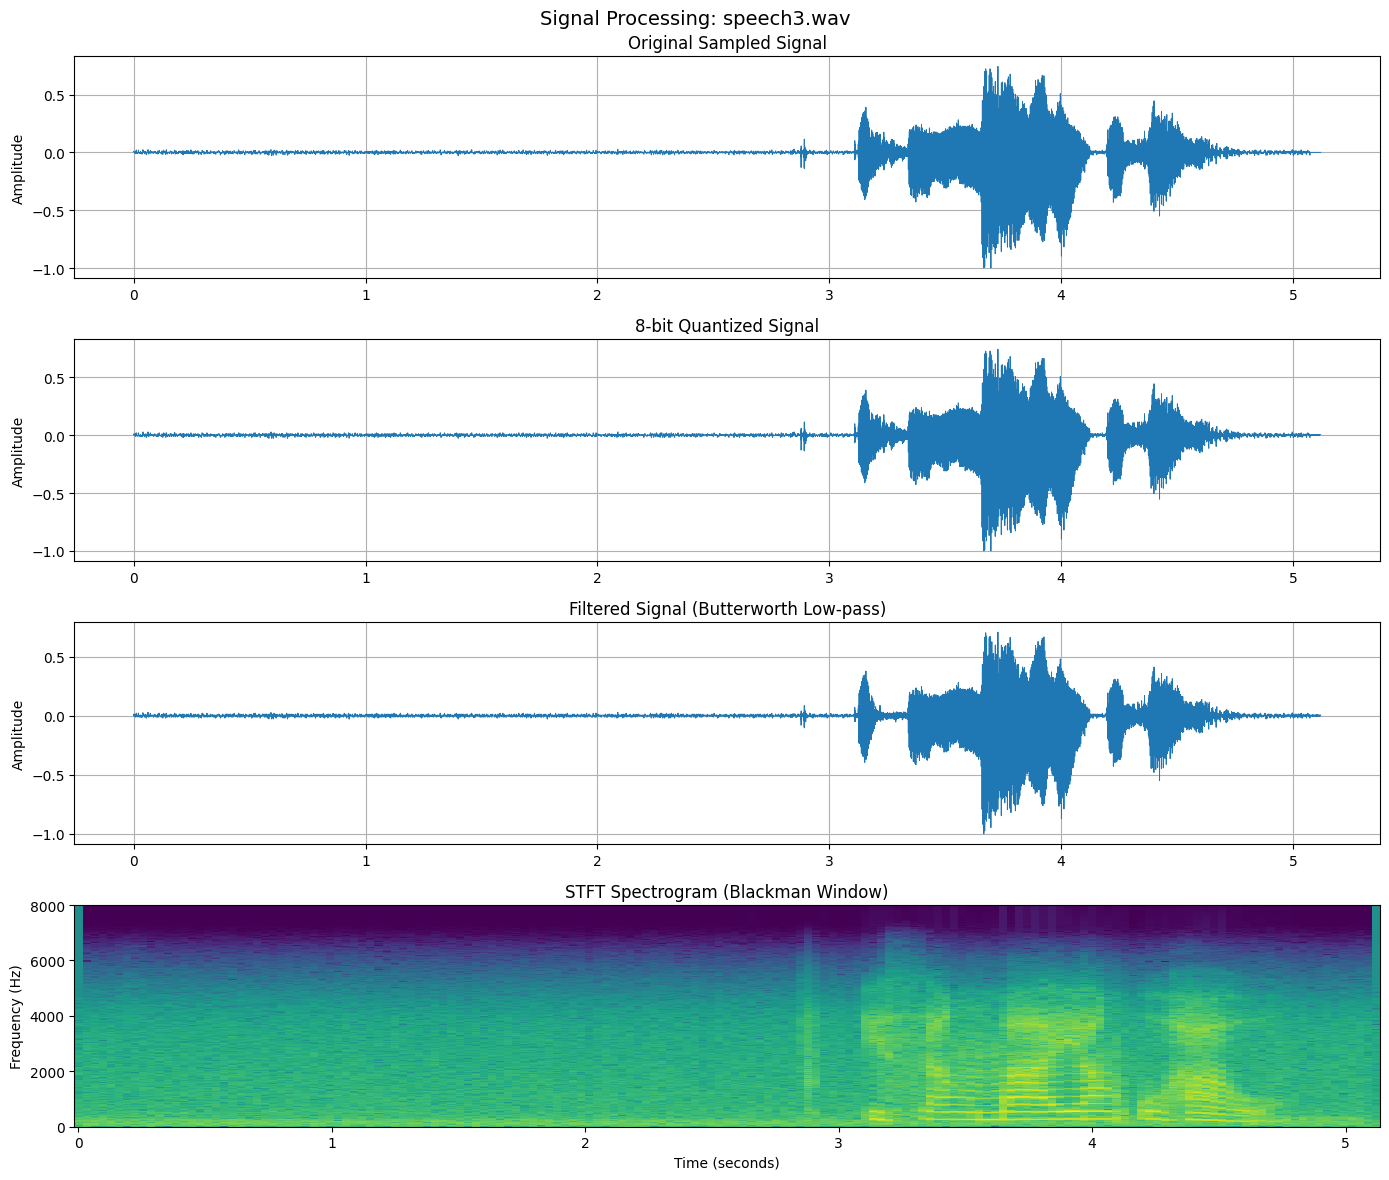


Signal processing completed.


In [ ]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import butter, sosfiltfilt, stft

# Folder path
folder_path = '/content/drive/MyDrive/CPE 027 - DSP Files/LAB 12/'

# Get the three WAV files
wav_files = sorted(glob.glob(os.path.join(folder_path, '*.wav')))[:3]

# Quantization settings
bits = 8
levels = 2 ** bits

# Filter settings
cutoff_frequency = 4000
filter_order = 4

if len(wav_files) < 3:
    print("Error: Three WAV files are required.")

else:
    for file_path in wav_files:

        print("\nProcessing:", os.path.basename(file_path))

        # 1. Read and sample the signal
        sr, data = wavfile.read(file_path)

        # Convert stereo to mono
        if data.ndim > 1:
            data = data.mean(axis=1)

        # Normalize signal
        data = data.astype(np.float64)
        max_amplitude = np.max(np.abs(data))

        if max_amplitude == 0:
            print("Skipping empty signal.")
            continue

        signal = data / max_amplitude

        print("Sampling Frequency:", sr, "Hz")
        print("Number of Samples:", len(signal))
        print("Duration:", len(signal) / sr, "seconds")

        # 2. Quantization (8-bit)
        quantized_index = np.round(
            (signal + 1) * (levels - 1) / 2
        )

        quantized_index = np.clip(
            quantized_index, 0, levels - 1
        )

        quantized_signal = (
            2 * quantized_index / (levels - 1)
        ) - 1

        # 3. Apply Butterworth low-pass filter
        cutoff = min(cutoff_frequency, 0.4 * sr)

        sos = butter(
            filter_order,
            cutoff,
            btype='lowpass',
            fs=sr,
            output='sos'
        )

        filtered_signal = sosfiltfilt(sos, quantized_signal)

        # 4. Apply Blackman window through STFT
        nperseg = min(1024, len(filtered_signal))

        frequencies, times, Zxx = stft(
            filtered_signal,
            fs=sr,
            window='blackman',
            nperseg=nperseg,
            noverlap=nperseg // 2
        )

        magnitude = np.abs(Zxx)

        # Plot results
        time = np.arange(len(signal)) / sr

        fig, axes = plt.subplots(4, 1, figsize=(14, 12))

        # Original sampled signal
        axes[0].plot(time, signal, linewidth=0.7)
        axes[0].set_title('Original Sampled Signal')
        axes[0].set_ylabel('Amplitude')
        axes[0].grid(True)

        # Quantized signal
        axes[1].plot(time, quantized_signal, linewidth=0.7)
        axes[1].set_title('8-bit Quantized Signal')
        axes[1].set_ylabel('Amplitude')
        axes[1].grid(True)

        # Filtered signal
        axes[2].plot(time, filtered_signal, linewidth=0.7)
        axes[2].set_title('Filtered Signal (Butterworth Low-pass)')
        axes[2].set_ylabel('Amplitude')
        axes[2].grid(True)

        # STFT using Blackman window
        axes[3].pcolormesh(
            times,
            frequencies,
            20 * np.log10(magnitude + 1e-10),
            shading='auto'
        )
        axes[3].set_title('STFT Spectrogram (Blackman Window)')
        axes[3].set_xlabel('Time (seconds)')
        axes[3].set_ylabel('Frequency (Hz)')

        plt.suptitle(
            f'Signal Processing: {os.path.basename(file_path)}',
            fontsize=14
        )

        plt.tight_layout()
        plt.show()

print("\nSignal processing completed.")


3. Then, using numpy, use STFT to transform the filtered signals into frequency domains. Then, compare the frequencies produced.


Processing: speech1.wav
Sampling Rate: 16000 Hz
Dominant Frequency: 281.25 Hz

Processing: speech2.wav
Sampling Rate: 16000 Hz
Dominant Frequency: 250.0 Hz

Processing: speech3.wav
Sampling Rate: 16000 Hz
Dominant Frequency: 265.625 Hz


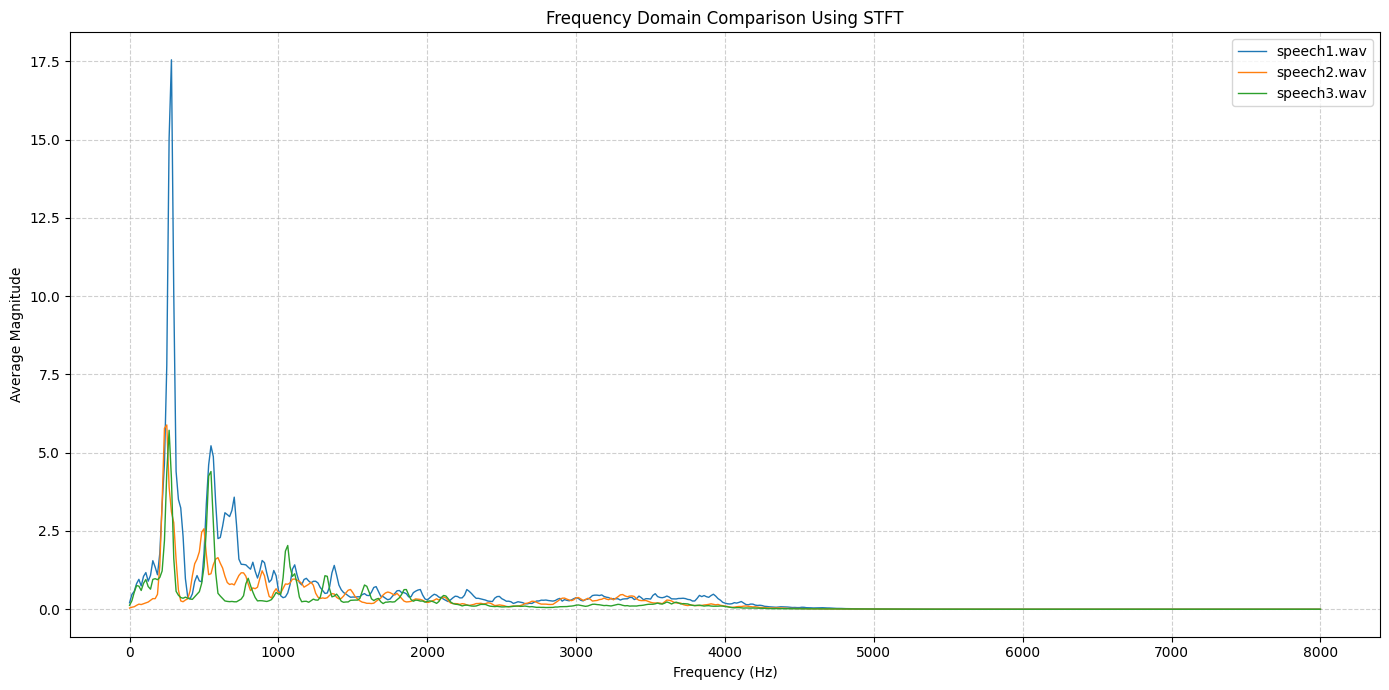


DOMINANT FREQUENCY COMPARISON
speech1.wav : 281.25 Hz
speech2.wav : 250.0 Hz
speech3.wav : 265.62 Hz


In [ ]:

import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import butter, sosfiltfilt

# Folder path
folder_path = '/content/drive/MyDrive/CPE 027 - DSP Files/LAB 12/'

# Get the three WAV files
wav_files = sorted(glob.glob(os.path.join(folder_path, '*.wav')))[:3]

# Settings
cutoff_frequency = 4000
filter_order = 4
nperseg = 1024
noverlap = 512

frequency_results = []

if len(wav_files) < 3:
    print("Error: Three WAV files are required.")

else:
    for file_path in wav_files:

        print("\nProcessing:", os.path.basename(file_path))

        # Read WAV file
        sr, data = wavfile.read(file_path)

        # Convert stereo to mono
        if data.ndim > 1:
            data = data.mean(axis=1)

        # Normalize signal
        data = data.astype(np.float64)
        max_amplitude = np.max(np.abs(data))

        if max_amplitude == 0:
            print("Skipping empty signal.")
            continue

        signal = data / max_amplitude

        # Apply Butterworth low-pass filter
        cutoff = min(cutoff_frequency, 0.4 * sr)

        sos = butter(
            filter_order,
            cutoff,
            btype='lowpass',
            fs=sr,
            output='sos'
        )

        filtered_signal = sosfiltfilt(sos, signal)

        # STFT using NumPy
        window = np.blackman(nperseg)

        hop_size = nperseg - noverlap

        # Divide signal into overlapping frames
        frames = np.array([
            filtered_signal[i:i+nperseg] * window
            for i in range(
                0,
                len(filtered_signal) - nperseg + 1,
                hop_size
            )
        ])

        # Calculate FFT for each frame
        fft_result = np.fft.rfft(frames, axis=1)

        # Calculate frequency values
        frequencies = np.fft.rfftfreq(nperseg, d=1/sr)

        # Calculate magnitude spectrum
        magnitude = np.abs(fft_result)

        # Average magnitude across all frames
        average_magnitude = np.mean(magnitude, axis=0)

        # Find dominant frequency
        dominant_index = np.argmax(average_magnitude)
        dominant_frequency = frequencies[dominant_index]

        frequency_results.append({
            'name': os.path.basename(file_path),
            'frequencies': frequencies,
            'magnitude': average_magnitude,
            'dominant_frequency': dominant_frequency
        })

        print("Sampling Rate:", sr, "Hz")
        print("Dominant Frequency:", dominant_frequency, "Hz")

    # Plot frequency comparison
    plt.figure(figsize=(14, 7))

    for result in frequency_results:
        plt.plot(
            result['frequencies'],
            result['magnitude'],
            label=result['name'],
            linewidth=1
        )

    plt.title('Frequency Domain Comparison Using STFT')
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Average Magnitude')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

    # Display dominant frequency comparison
    print("\nDOMINANT FREQUENCY COMPARISON")
    print("=" * 45)

    for result in frequency_results:
        print(
            result['name'],
            ":",
            round(result['dominant_frequency'], 2),
            "Hz"
        )


4. Create a spectrogram for each created frequency graphs. Analyze the produced images.


Generating spectrogram: speech1.wav


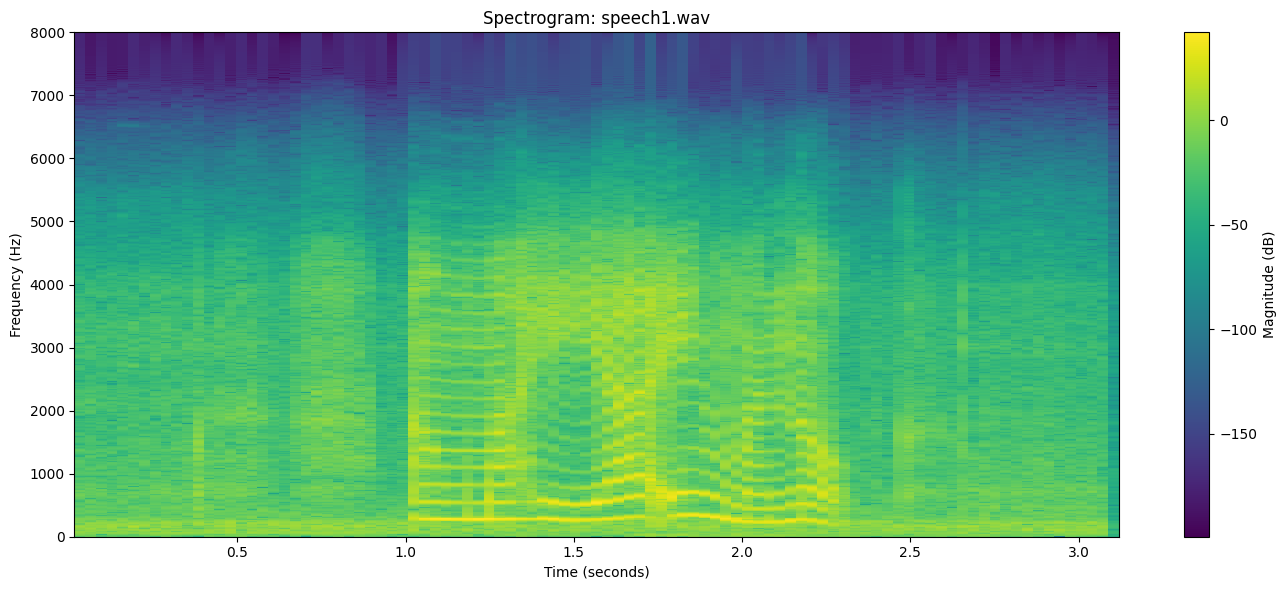


Generating spectrogram: speech2.wav


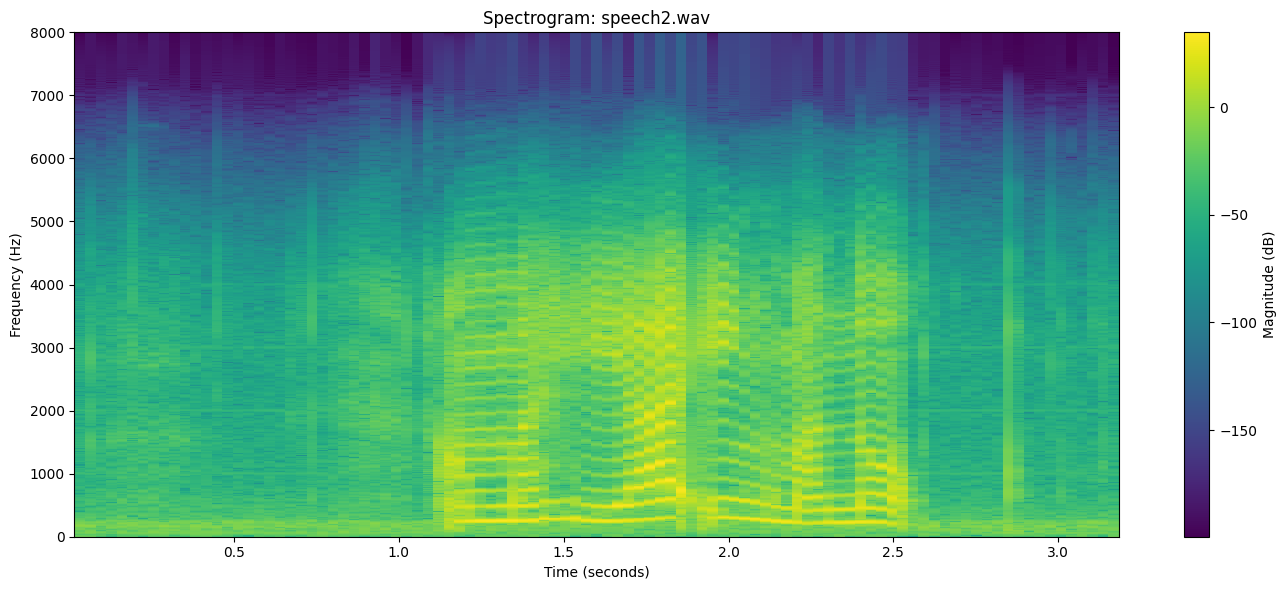


Generating spectrogram: speech3.wav


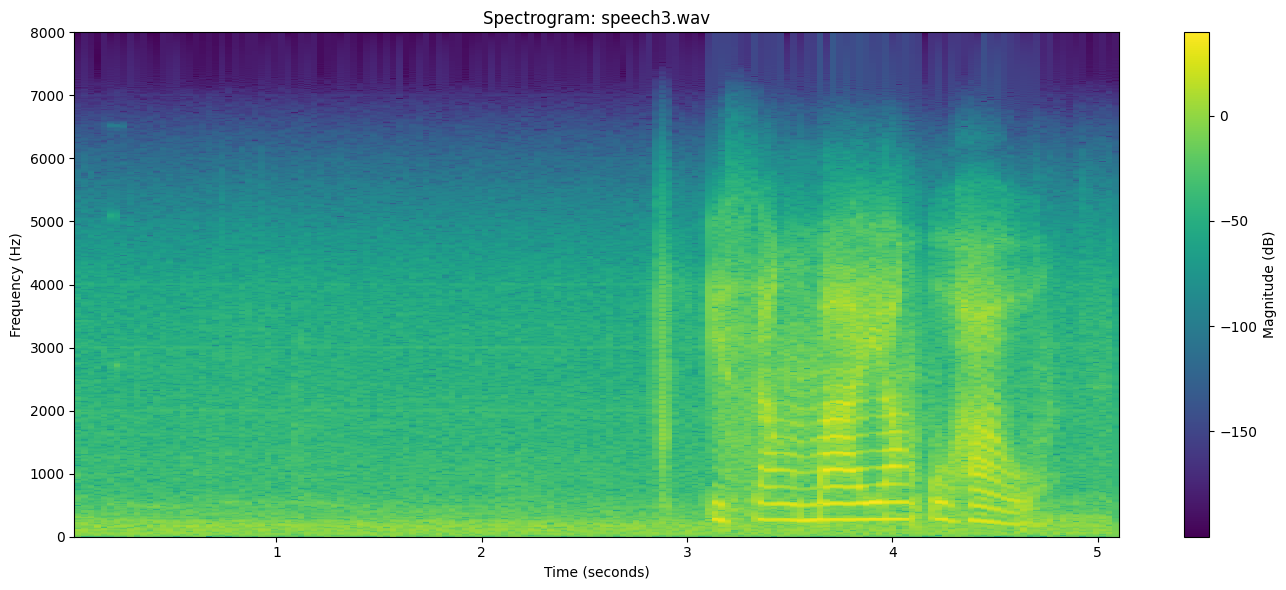


Spectrogram generation completed.


In [ ]:

import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import butter, sosfiltfilt

# Folder path
folder_path = '/content/drive/MyDrive/CPE 027 - DSP Files/LAB 12/'

# Get the three WAV files
wav_files = sorted(glob.glob(os.path.join(folder_path, '*.wav')))[:3]

# STFT settings
nperseg = 1024
noverlap = 512
hop_size = nperseg - noverlap

# Filter settings
cutoff_frequency = 4000
filter_order = 4

if len(wav_files) < 3:
    print("Error: Three WAV files are required.")

else:
    for file_path in wav_files:

        print("\nGenerating spectrogram:", os.path.basename(file_path))

        # Read WAV file
        sr, data = wavfile.read(file_path)

        # Convert stereo to mono
        if data.ndim > 1:
            data = data.mean(axis=1)

        # Normalize signal
        data = data.astype(np.float64)
        max_amplitude = np.max(np.abs(data))

        if max_amplitude == 0:
            print("Skipping empty signal.")
            continue

        signal = data / max_amplitude

        # Apply Butterworth low-pass filter
        cutoff = min(cutoff_frequency, 0.4 * sr)

        sos = butter(
            filter_order,
            cutoff,
            btype='lowpass',
            fs=sr,
            output='sos'
        )

        filtered_signal = sosfiltfilt(sos, signal)

        # Apply Blackman window
        window = np.blackman(nperseg)

        # Divide signal into overlapping frames
        frames = np.array([
            filtered_signal[i:i+nperseg] * window
            for i in range(
                0,
                len(filtered_signal) - nperseg + 1,
                hop_size
            )
        ])

        # Calculate STFT using NumPy FFT
        fft_result = np.fft.rfft(frames, axis=1)

        # Frequency and time axes
        frequencies = np.fft.rfftfreq(nperseg, d=1/sr)

        times = (
            np.arange(len(frames)) * hop_size
            + nperseg / 2
        ) / sr

        # Calculate magnitude in decibels
        magnitude = np.abs(fft_result)
        spectrogram_db = 20 * np.log10(magnitude + 1e-10)

        # Plot individual spectrogram
        plt.figure(figsize=(14, 6))

        plt.pcolormesh(
            times,
            frequencies,
            spectrogram_db.T,
            shading='auto',
            cmap='viridis'
        )

        plt.title(
            f'Spectrogram: {os.path.basename(file_path)}'
        )
        plt.xlabel('Time (seconds)')
        plt.ylabel('Frequency (Hz)')
        plt.colorbar(label='Magnitude (dB)')
        plt.ylim(0, sr / 2)

        plt.tight_layout()
        plt.show()

print("\nSpectrogram generation completed.")
